# Model Training

In [ ]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, precision_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

DATA_DIR = Path("../Data")

df = pd.read_csv(DATA_DIR / "twcs_filtered_labeled_1_cleaned.csv")
df.head()

,text,label
0,the correct way to do it is via an ocs accoun...,Account & Plan Management
1,what else can i provide they refuse to help m...,Account & Plan Management
2,how i have my phone number and email thats it...,Device & Technical Support
3,dont know router is downstairs but its just t...,Device & Technical Support
4,just randomly boots me offline there it goes ...,Network & Connectivity


In [14]:
# Splitting data into 80% training and 20% validation
X = df['text']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training tweets:", X_train.shape)
print("Validation tweets:", X_test.shape)
print("Training labels:", y_train.shape)
print("Validation labels:", y_test.shape)

Training tweets: (19142,)
Validation tweets: (4786,)
Training labels: (19142,)
Validation labels: (4786,)


## Creating class weights & TF-IDF Vectorization

In [15]:
# Creating a weight dictionary for data training to ensure all labels get equal attention
labels = list(df['label'].unique())
count = df['label'].value_counts()

label_counts = []
for i in labels:
  label_counts.append(count[i])

def weight(N, C, samples):
    label_weight = N/(C*samples)
    return label_weight

weights_dict = {}

N = len(df)
C = len(labels)

for label in labels:
  samples = count[label]
  label_weight = weight(N, C, samples)
  weights_dict[label] = label_weight

weights_dict

{'Account & Plan Management': np.float64(1.827262313860252),
 'Device & Technical Support': np.float64(0.46072975835178587),
 'Network & Connectivity': np.float64(0.7864585045193098),
 'Billing & Payment': np.float64(1.5497409326424871),
 'Cancellation & Retention': np.float64(2.7361921097770154)}

In [ ]:
# Prepare data for model training: TF-IDF vectorization
vectorizer = TfidfVectorizer()
X_train = vectorizer.fit_transform(X_train)
X_test = vectorizer.transform(X_test)

## Logistic Regression Model

In [17]:
# Train Logistic Regression using TF-IDF features and existing class weights
lr_model = LogisticRegression(
    class_weight=weights_dict,
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")
print("Training samples:", X_train.shape[0])
print("Number of TF-IDF features:", X_train.shape[1])

Logistic Regression model trained successfully!
Training samples: 19142
Number of TF-IDF features: 13210


In [18]:
# Evaluate Logistic Regression on the validation dataset

# Predict labels for validation tweets
y_pred = lr_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Validation Accuracy: {accuracy:.4f}")

# Display precision, recall, and F1 scores for each category
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Validation Accuracy: 0.9860

Classification Report:
                            precision    recall  f1-score   support

 Account & Plan Management       1.00      0.98      0.99       524
         Billing & Payment       0.97      0.99      0.98       618
  Cancellation & Retention       0.99      0.98      0.98       350
Device & Technical Support       0.99      0.99      0.99      2077
    Network & Connectivity       0.98      0.99      0.98      1217

                  accuracy                           0.99      4786
                 macro avg       0.98      0.98      0.98      4786
              weighted avg       0.99      0.99      0.99      4786



In [19]:
# Compare actual labels with Logistic Regression predictions
results = pd.DataFrame({
    "Actual Label": y_test,
    "Predicted Label": y_pred
})

results["Correct"] = results["Actual Label"] == results["Predicted Label"]

results.sample(10)

,Actual Label,Predicted Label,Correct
9262,Network & Connectivity,Network & Connectivity,True
21440,Device & Technical Support,Device & Technical Support,True
8798,Device & Technical Support,Device & Technical Support,True
6313,Network & Connectivity,Network & Connectivity,True
13325,Device & Technical Support,Device & Technical Support,True
10041,Network & Connectivity,Network & Connectivity,True
19467,Network & Connectivity,Network & Connectivity,True
23027,Device & Technical Support,Device & Technical Support,True
17716,Account & Plan Management,Account & Plan Management,True
12573,Account & Plan Management,Account & Plan Management,True


In [20]:
# Check for identical tweets across training and validation
train_texts = df.loc[y_train.index, "text"]
val_texts = df.loc[y_test.index, "text"]

duplicates = set(train_texts) & set(val_texts)

print("Unique tweets appearing in both sets:", len(duplicates))
print("Validation rows with text seen during training:",
      val_texts.isin(set(train_texts)).sum())

Unique tweets appearing in both sets: 22
Validation rows with text seen during training: 29


In [21]:
# Check model predictions for duplicate tweets in validation
duplicate_mask = val_texts.isin(set(train_texts))

duplicate_results = results.loc[duplicate_mask]

print("Duplicate validation tweets:", len(duplicate_results))

print("Correct predictions:",
      duplicate_results["Correct"].sum())

print("Incorrect predictions:",
      (~duplicate_results["Correct"]).sum())

duplicate_results.head(10)

Duplicate validation tweets: 29
Correct predictions: 29
Incorrect predictions: 0


,Actual Label,Predicted Label,Correct
12558,Account & Plan Management,Account & Plan Management,True
15719,Network & Connectivity,Network & Connectivity,True
563,Billing & Payment,Billing & Payment,True
6159,Device & Technical Support,Device & Technical Support,True
12685,Account & Plan Management,Account & Plan Management,True
7721,Device & Technical Support,Device & Technical Support,True
14218,Network & Connectivity,Network & Connectivity,True
22244,Billing & Payment,Billing & Payment,True
10794,Device & Technical Support,Device & Technical Support,True
18963,Account & Plan Management,Account & Plan Management,True


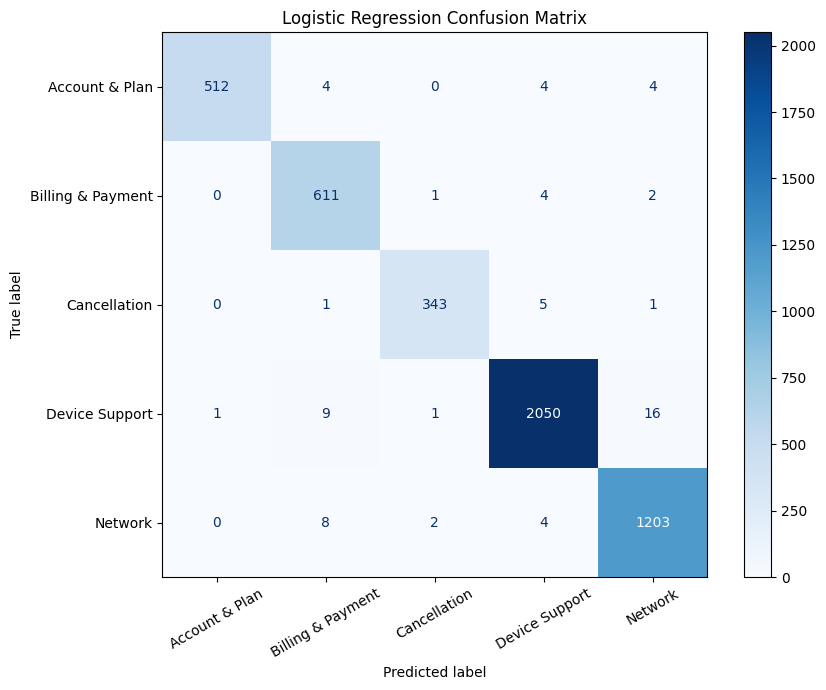

In [22]:
# Evaluate Logistic Regression using a confusion matrix

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=lr_model.classes_)

# Shorten category names for better visualization
short_labels = [
    "Account & Plan",
    "Billing & Payment",
    "Cancellation",
    "Device Support",
    "Network"
]

# Display confusion matrix
fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=short_labels
)

disp.plot(
    cmap="Blues",
    ax=ax,
    xticks_rotation=30,
    values_format="d"
)

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

In [23]:
# Inspect the top 10 positively weighted TF-IDF features for Network & Connectivity
category = "Cancellation & Retention"

class_index = list(lr_model.classes_).index(category)

coefficients = lr_model.coef_[class_index]

feature_names = vectorizer.get_feature_names_out()

top_indices = np.argsort(coefficients)[-10:][::-1]

for index in top_indices:
    print(feature_names[index], round(coefficients[index], 3))

switch 15.228
cancel 12.132
switching 11.878
leaving 8.971
cancelled 7.867
cancelling 6.981
port 6.856
canceling 6.53
canceled 5.811
cancellation 3.83


## Random Forest Model

In [24]:
# Hyperparameter tuning for Random Forest model using GridSearchCV
# Commented out because it takes too long to run; see output/next cell for the optimal hyperparameter values

"""
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

trees = [100 * n for n in range (1, 4)]
depths = [2**n for n in range(2, 5)]
leaves = [25 * 2**n for n in range(0, 3)]
rf_params_grid = {"n_estimators": trees, "max_depth": depths, "min_samples_split": leaves}

base_rf_model = RandomForestClassifier(class_weight=weights_dict, random_state=42)

rf_grid = GridSearchCV(base_rf_model, rf_params_grid, cv=5, n_jobs=-1)

rf_grid_search = rf_grid.fit(X_train, y_train)
rf_grid_search.best_params_
"""

'\nfrom sklearn.ensemble import RandomForestClassifier\nfrom sklearn.model_selection import GridSearchCV\n\ntrees = [100 * n for n in range (1, 4)]\ndepths = [2**n for n in range(2, 5)]\nleaves = [25 * 2**n for n in range(0, 3)]\nrf_params_grid = {"n_estimators": trees, "max_depth": depths, "min_samples_split": leaves}\n\nbase_rf_model = RandomForestClassifier(class_weight=weights_dict, random_state=42)\n\nrf_grid = GridSearchCV(base_rf_model, rf_params_grid, cv=5, n_jobs=-1)\n\nrf_grid_search = rf_grid.fit(X_train, y_train)\nrf_grid_search.best_params_\n'

In [25]:
# Training Random Forest model with tuned hyperparameters
rf_model = RandomForestClassifier(n_estimators=300,
                               max_depth=16,
                               min_samples_split=25,
                               class_weight=weights_dict,
                               random_state=42)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

In [26]:
# Displaying accuracy, f1, and precision for Random Forest model
rf_accuracy = accuracy_score(y_test, rf_predictions)
rf_f1 = f1_score(y_test, rf_predictions, average='weighted')
rf_precision = precision_score(y_test, rf_predictions, average='weighted')

rf_accuracy, rf_f1, rf_precision

(0.9657333890513999, 0.9658954559856088, 0.9664209573389951)

In [27]:
# Print classification report for Random Forest Model
print(classification_report(y_test, rf_predictions))

                            precision    recall  f1-score   support

 Account & Plan Management       0.96      0.97      0.96       524
         Billing & Payment       0.96      0.96      0.96       618
  Cancellation & Retention       0.90      0.97      0.94       350
Device & Technical Support       0.99      0.96      0.98      2077
    Network & Connectivity       0.95      0.97      0.96      1217

                  accuracy                           0.97      4786
                 macro avg       0.95      0.97      0.96      4786
              weighted avg       0.97      0.97      0.97      4786



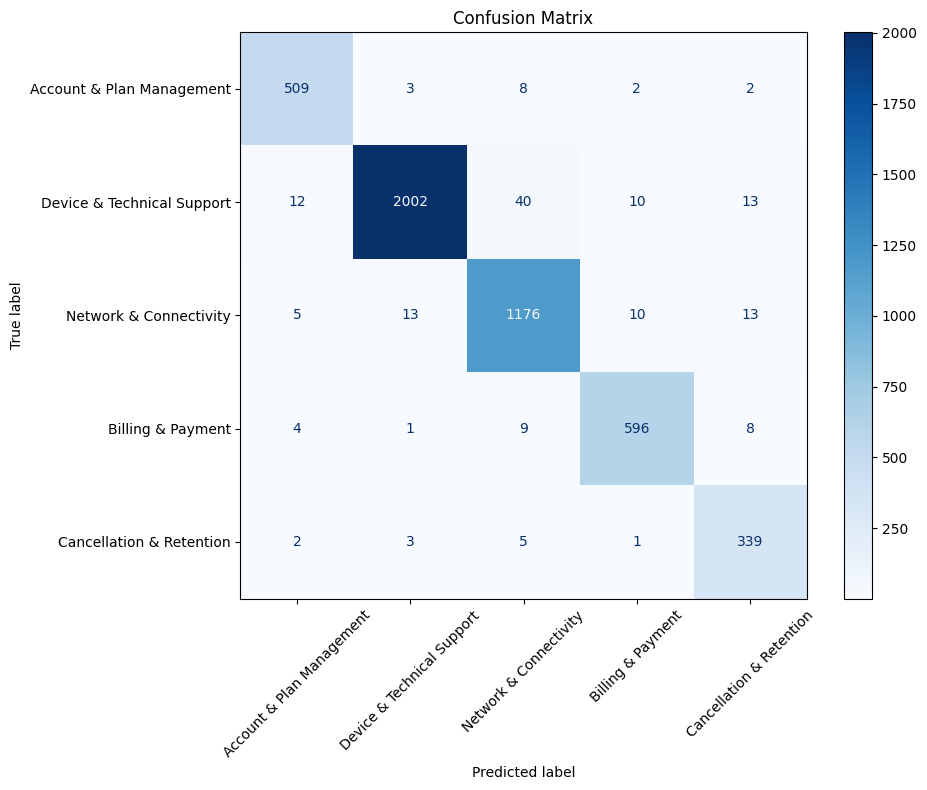

In [28]:
# Displaying confusion matrix for Random Forest model
categories = list(weights_dict.keys())

rf_confusion_matrix = confusion_matrix(y_test, rf_predictions, labels=categories)
rf_disp = ConfusionMatrixDisplay(confusion_matrix=rf_confusion_matrix, display_labels=categories)

fig, ax = plt.subplots(figsize=(10, 8))
rf_disp.plot(ax=ax, cmap='Blues', xticks_rotation=45)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

## Naive Bayes Model

Accuracy: 0.6870

Classification Report:
                            precision    recall  f1-score   support

 Account & Plan Management       1.00      0.19      0.32       524
         Billing & Payment       0.99      0.28      0.44       618
  Cancellation & Retention       1.00      0.08      0.14       350
Device & Technical Support       0.59      0.99      0.74      2077
    Network & Connectivity       0.94      0.77      0.85      1217

                  accuracy                           0.69      4786
                 macro avg       0.90      0.46      0.50      4786
              weighted avg       0.81      0.69      0.64      4786



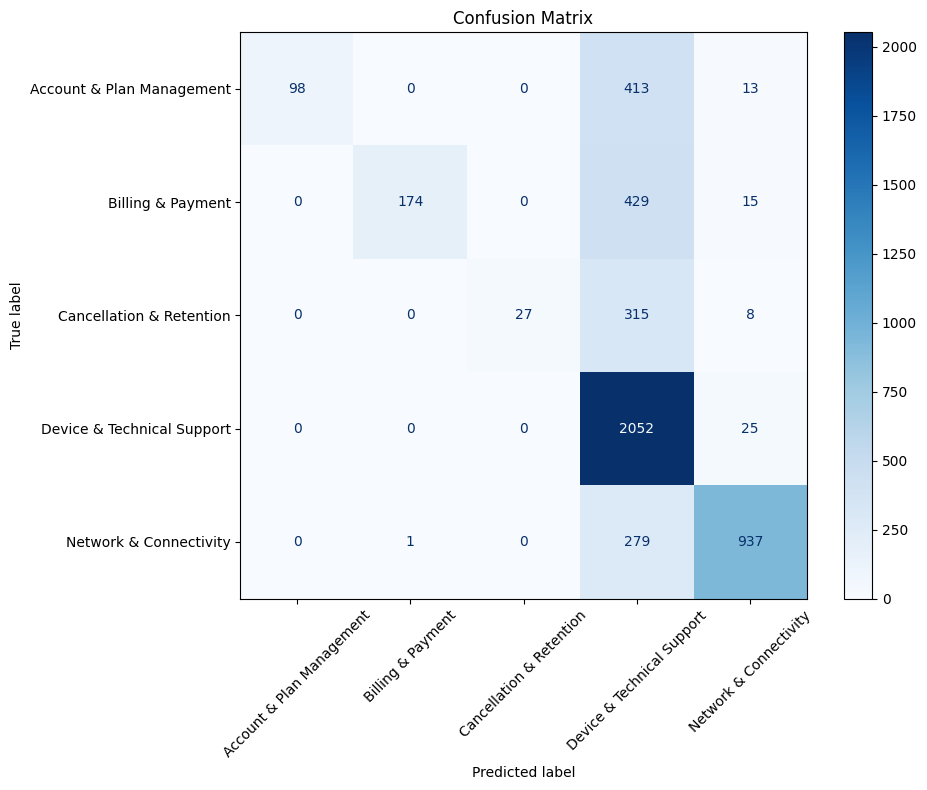

In [29]:
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

nb_predictions = nb_model.predict(X_test)

nb_accuracy = accuracy_score(y_test, nb_predictions)
print(f"Accuracy: {nb_accuracy:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, nb_predictions))

nb_cm = confusion_matrix(y_test, nb_predictions, labels=nb_model.classes_)
nb_disp = ConfusionMatrixDisplay(confusion_matrix=nb_cm, display_labels=nb_model.classes_)

fig, ax = plt.subplots(figsize=(10, 8))
nb_disp.plot(ax=ax, cmap='Blues', xticks_rotation=45)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

## Model Comparison

In [30]:
# Compare Logistic Regression, Naive Bayes, and Random Forest
models = {
    "Logistic Regression": lr_model,
    "Naive Bayes": nb_model,
    "Random Forest": rf_model,
}

results = []

for name, clf in models.items():
    predictions = clf.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(y_test, predictions, average="macro"),
        "Weighted F1": f1_score(y_test, predictions, average="weighted"),
        "Macro Precision": precision_score(y_test, predictions, average="macro"),
        "Weighted Precision": precision_score(y_test, predictions, average="weighted")
    })

comparison_df = pd.DataFrame(results)

display(comparison_df)

,Model,Accuracy,Macro F1,Weighted F1,Macro Precision,Weighted Precision
0,Logistic Regression,0.986001,0.984547,0.986021,0.984957,0.986116
1,Naive Bayes,0.687004,0.496141,0.636819,0.904293,0.805054
2,Random Forest,0.965733,0.959536,0.965895,0.952728,0.966421


In [31]:
# Export the most optimal model
pkl_model_filename = "lr_model.pkl"
pickle.dump(lr_model, open("../models/" + pkl_model_filename, "wb"))